<a href="https://colab.research.google.com/github/LuisFelipeVelasco/ML_And_Generative_AI_Experiments/blob/main/Matrix%20Manipulation/Matrix_Manipulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Matrix_Manipulation**
The notebook will work on different taskes using some matrix manipulation operations

**IMPORT LIBRARIES**

In [1]:
import numpy as np
import cv2
import math
from google.colab.patches import cv2_imshow

**IMPORT RESOURCES**

Loading Images
--2026-10-29 15:58:19--  http://raw.githubusercontent.com/LuisFelipeVelasco/ML_And_Generative_AI_Experiments/main/Matrix%20Manipulation/Images/left.png
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.110.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:80... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://raw.githubusercontent.com/LuisFelipeVelasco/ML_And_Generative_AI_Experiments/main/Matrix%20Manipulation/Images/left.png [following]
--2026-10-29 15:58:19--  https://raw.githubusercontent.com/LuisFelipeVelasco/ML_And_Generative_AI_Experiments/main/Matrix%20Manipulation/Images/left.png
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1184684 (1.1M) [image/png]
Saving to: ‘left.png’

left.png            100%[===========

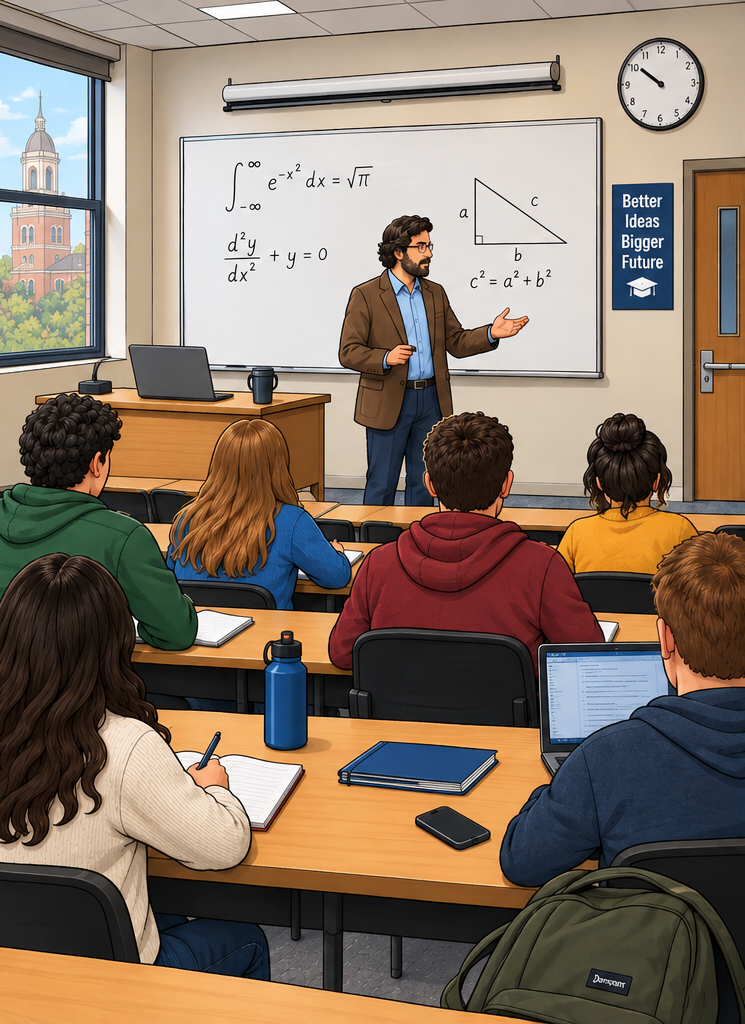

Image 2:


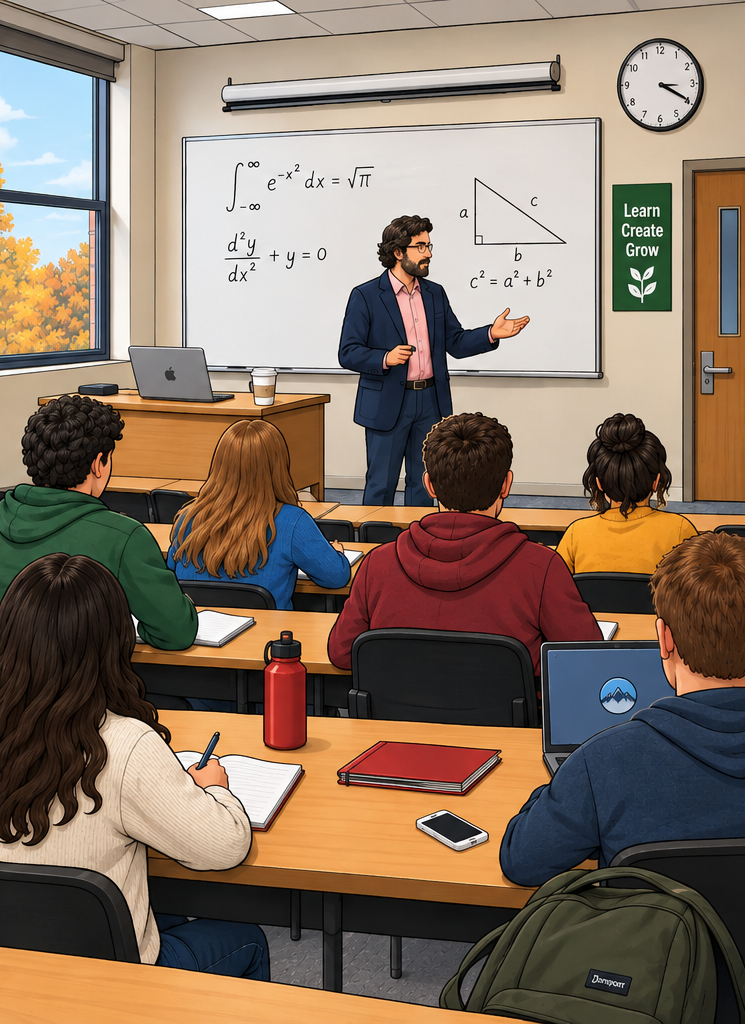

Object 1:


Object 2:


Object 3:


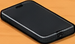

Object 4:


In [2]:
print("Loading Images")

!wget raw.githubusercontent.com/LuisFelipeVelasco/ML_And_Generative_AI_Experiments/main/Matrix%20Manipulation/Images/left.png
img_1=cv2.imread('left.png')
!wget raw.githubusercontent.com/LuisFelipeVelasco/ML_And_Generative_AI_Experiments/main/Matrix%20Manipulation/Images/right.png
img_2=cv2.imread('right.png')

!wget raw.githubusercontent.com/LuisFelipeVelasco/ML_And_Generative_AI_Experiments/main/Matrix%20Manipulation/Images/Object-1.png
object_1=cv2.imread('Object-1.png')

!wget raw.githubusercontent.com/LuisFelipeVelasco/ML_And_Generative_AI_Experiments/main/Matrix%20Manipulation/Images/Object-2.png
object_2=cv2.imread('Object-2.png')

!wget raw.githubusercontent.com/LuisFelipeVelasco/ML_And_Generative_AI_Experiments/main/Matrix%20Manipulation/Images/Object-3.png
object_3=cv2.imread('Object-3.png')

!wget raw.githubusercontent.com/LuisFelipeVelasco/ML_And_Generative_AI_Experiments/main/Matrix%20Manipulation/Images/Object-4.png
object_4=cv2.imread('Object-4.png')

print("Image 1:")
cv2_imshow(img_1)
print("Image 2:")
cv2_imshow(img_2)
print("Object 1:")
cv2_imshow(object_1)
print("Object 2:")
cv2_imshow(object_2)
print("Object 3:")
cv2_imshow(object_3)
print("Object 4:")
cv2_imshow(object_4)

# **TASK 1 : FIND THE DIFFERENCES BETWEEN TWO IMAGES**


**FIND DIFFERENCES USING SUBSTRACTION METHOD**

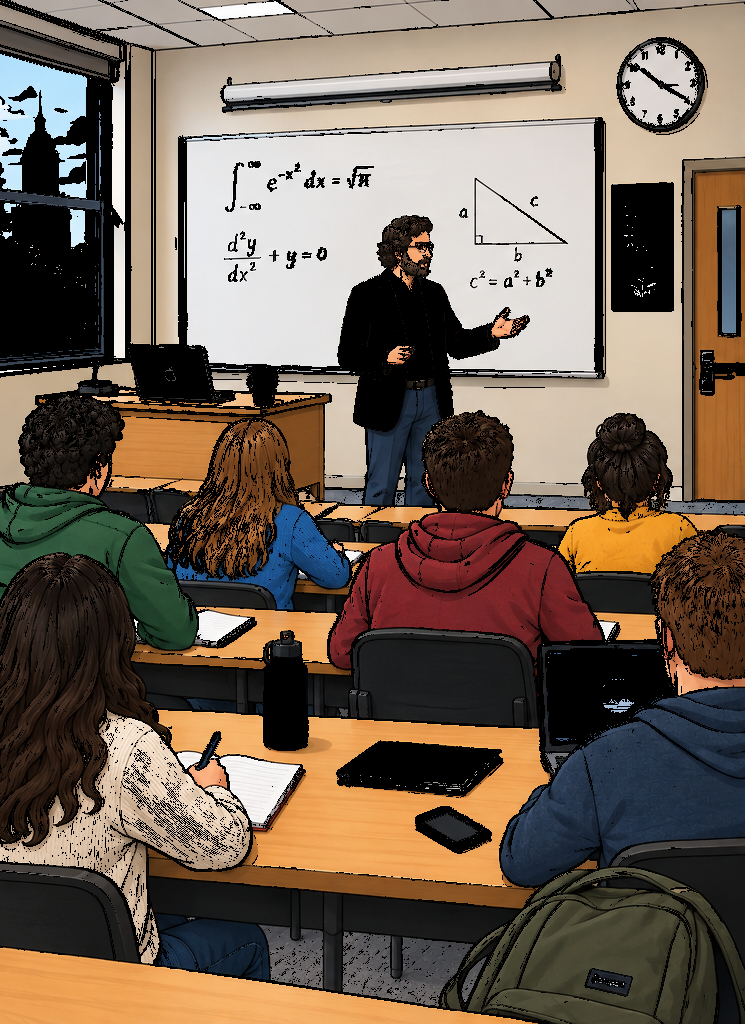

In [7]:
#The difference of the images is calculated to see how they differ each other

#substraction = np.abs(img_1-img_2)
substraction = np.abs(cv2.subtract(img_1, img_2, dtype=cv2.CV_16S))
mask_shape=(substraction.shape[0],substraction.shape[1])
mask=np.zeros(mask_shape,dtype=np.uint8)
difference=np.zeros(mask_shape)

#If the difference of each BGR component in each pixel is less then max_difference, then it is not count as a difference
#Each part of the image classified as a difference is substituted for a black pixel

max_difference=20
for i in range(substraction.shape[0]):
  for j in range(substraction.shape[1]):
    if substraction[i,j,0]<max_difference and substraction[i,j,1]<max_difference and substraction[i,j,2]<max_difference:
      mask[i,j]=255
result=cv2.bitwise_and(img_1,img_1,mask=mask)
cv2_imshow(result)

Substraction method find differences based on pixel color/intesity values.A little variation of this components between images can make that pixel be classified as a clear difference. Then ,**it is not a suitable method to identify object changes and discard minor appearance variations**

# **TASK 2 : FIND OBJECTS IN A IMAGE**

**FIND OBJECTS IN A IMAGE USING ONE CONVOLUTION**

Choose an object : 1) Bottle , 2) Y letter , 3) Phone , 4) Hat   3
Detecting object ...
Detection finished


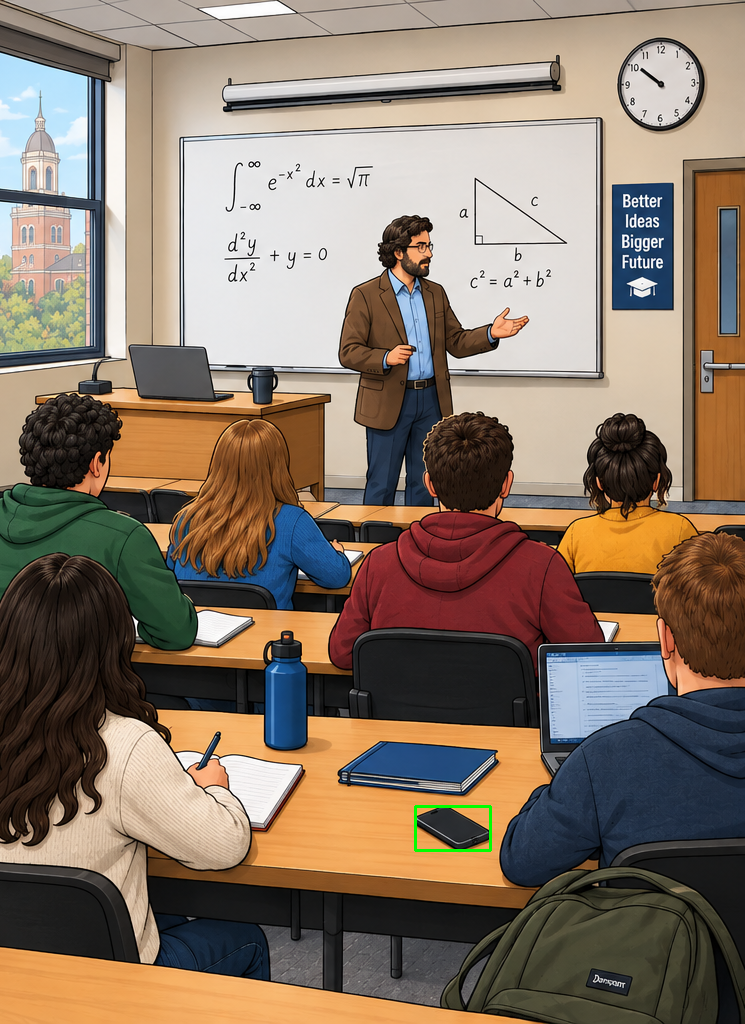

In [5]:
while True:
  n_object=input("Choose an object : 1) Bottle , 2) Y letter , 3) Phone , 4) Hat   ")
  if(n_object=="1"):
    _object=object_1
    break
  elif(n_object=="2"):
    _object=object_2
    break
  elif(n_object=="3"):
    _object=object_3
    break
  elif(n_object=="4"):
    _object=object_4
    break
  else:
    print("Invalid input")

print("Detecting object ...")
#The image is converting to gray scale to deal with just one component (intensity)
gray_image=cv2.cvtColor(img_1,cv2.COLOR_BGR2GRAY).astype(np.float64)
gray_object=cv2.cvtColor(_object,cv2.COLOR_BGR2GRAY).astype(np.float64)

#Substituting 0 pixels  for 0.1 to avoid divisions over 0

gray_object_rows=gray_object.shape[0]
gray_object_columns=gray_object.shape[1]
for i in range(gray_object_rows):
  for j in range(gray_object_columns):
    if(gray_object[i][j]==0):
      gray_object[i][j]=0.1

gray_image_rows=gray_image.shape[0]
gray_image_columns=gray_image.shape[1]
for i in range(gray_image_rows):
  for j in range(gray_image_columns):
    if(gray_image[i][j]==0):
      gray_image[i][j]=0.1

#Setting variables to do the convolution
kernel_object=(1/(gray_object)).astype(np.float64)
best_element_wise_opearation=0
kernel_object_columns=kernel_object.shape[1]
kernel_object_rows=kernel_object.shape[0]

#The kernel (the reciprocal of the object image) will iterate the image to operate how similar is each region of the image with the object
#The closer is the result of element-wise operation to the size of the kernel  , the more similar is that current piece of the image to the object
#End up saving the first pixel´s coordinates of the sub-image most similiar to the object

for i in range(gray_image_rows-kernel_object_rows):
  for j in range(gray_image_columns-kernel_object_columns):
    subimage= gray_image[i:i+kernel_object_rows,j:j+kernel_object_columns].astype(np.float64)
    element_wise_operation=np.sum(kernel_object*subimage)
    size_kernel=kernel_object.size
    if(np.abs(element_wise_operation-size_kernel)<np.abs(best_element_wise_opearation-size_kernel)):
      best_element_wise_opearation=element_wise_operation
      first_object_row=i
      first_object_column=j

#Draw a square around the object detected on the image
print("Detection finished")
img_copy=img_1.copy()
cv2.rectangle(img_copy,(first_object_column,first_object_row),(first_object_column+kernel_object_columns,first_object_row+kernel_object_rows),(0,255,0),2)
cv2_imshow(img_copy)




The algorithm performs well because it predicts the position of an object  by comparing the similarity of each region in the background picture with the input image.However, the less similar the provided object image is to the target object in the background picture , the lower the accuracy of the algorithm will be.**Therefore, the algorithm is a good option for finding an object in a picture when the object's region in the same picture is given, in other cases probably will not work.**